# Linear Regression on California Housing Prices

**Objective:** Predict median house value using median income with a simple linear regression model.

## 1. Import the libraries

I use:
- **pandas** to load and inspect the dataset.
- **NumPy** for numerical operations.
- **Matplotlib** to create visualizations.
- **scikit-learn** to split the data, train Linear Regression, and calculate evaluation metrics.

In [ ]:
# Install the required packages using pip. You can run this command in your terminal or command prompt to install all the dependencies listed in the requirements.txt file.
# %pip install -r requirements.txt

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Make plots appear inside the notebook
%matplotlib inline

## 2. Load the dataset

Read `housing.csv` into a pandas DataFrame and inspect the first few rows. This helps confirm that the file was loaded correctly and shows the available columns.

In [3]:
df = pd.read_csv("housing.csv")

print("Dataset shape (rows, columns):", df.shape)
display(df.head())

Dataset shape (rows, columns): (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


**Interpretation:** The shape output reports the number of records and columns. The table preview lets you check that the expected fields, including `median_income` and `median_house_value`, are present.

## 3. Select exactly two variables and clean missing values

For this assignment, only two columns are used:
- **X (independent variable):** `median_income`
- **y (dependent variable):** `median_house_value`

Rows missing either selected value are removed. Other columns are not used by the model.

In [4]:
selected_columns = ["median_income", "median_house_value"]
data = df[selected_columns].dropna().copy()

print("Records before cleaning:", len(df))
print("Records after removing missing selected values:", len(data))
print("Records removed:", len(df) - len(data))

display(data.head())

Records before cleaning: 20640
Records after removing missing selected values: 20640
Records removed: 0


,median_income,median_house_value
0,8.3252,452600.0
1,8.3014,358500.0
2,7.2574,352100.0
3,5.6431,341300.0
4,3.8462,342200.0


## 4. Explore the relationship visually

A scatter plot shows each district as a point. Median income is on the X-axis and median house value is on the Y-axis. This is a preliminary look at whether higher income tends to be associated with higher house values.

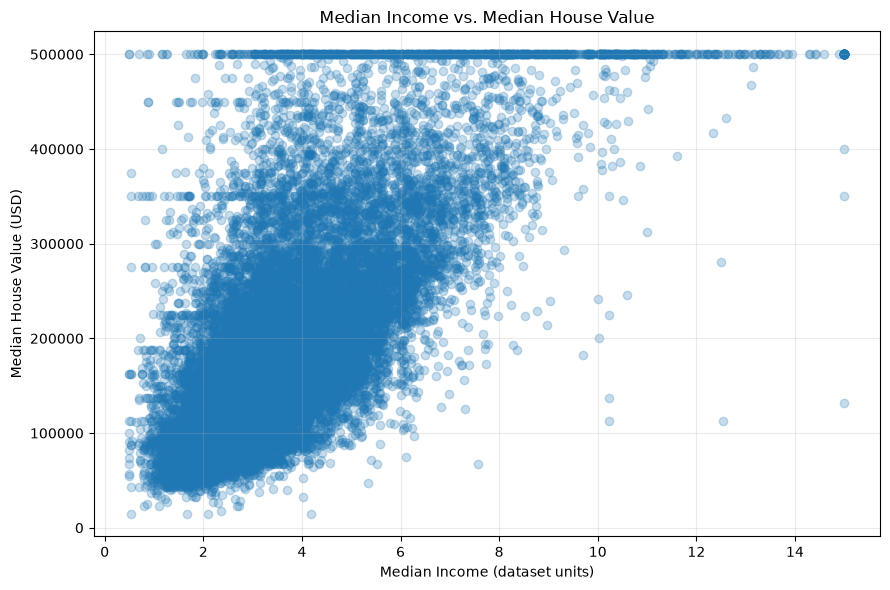

In [5]:
plt.figure(figsize=(9, 6))
plt.scatter(
    data["median_income"],
    data["median_house_value"],
    alpha=0.25
)
plt.xlabel("Median Income (dataset units)")
plt.ylabel("Median House Value (USD)")
plt.title("Median Income vs. Median House Value")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretation:** Look for the overall direction of the points. An upward pattern suggests a positive association: districts with higher median income often have higher median house values. The points will not fall perfectly on a straight line because house values are affected by other factors too.

## 5. Split the data into training and testing sets

The assignment specifies an 80/20 split. The model learns from the 80% training set; the 20% test set is held back for evaluation. `random_state=42` makes the split reproducible.

In [6]:
X = data[["median_income"]]
y = data["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print(f"Total usable records: {len(data):,}")
print(f"Training records (80%): {len(X_train):,}")
print(f"Testing records (20%): {len(X_test):,}")

Total usable records: 20,640
Training records (80%): 16,512
Testing records (20%): 4,128


**Interpretation:** The training and testing counts should add up to the total usable record count. The test set is not used to fit the model; it is used to measure how well the trained model predicts unseen observations.

## 6. Train the Linear Regression model

Linear Regression fits a straight line of the form:

\[
\hat{y} = b_0 + b_1x
\]

Here, \(x\) is median income, \(\hat{y}\) is predicted median house value, \(b_0\) is the intercept, and \(b_1\) is the slope.

In [7]:
model = LinearRegression()
model.fit(X_train, y_train)

intercept = model.intercept_
slope = model.coef_[0]

print(f"Intercept (b0): ${intercept:,.2f}")
print(f"Slope (b1): ${slope:,.2f}")
print(
    f"Regression equation: Predicted house value = "
    f"{intercept:,.2f} + ({slope:,.2f} × median income)"
)

Intercept (b0): $44,459.73
Slope (b1): $41,933.85
Regression equation: Predicted house value = 44,459.73 + (41,933.85 × median income)


**Interpretation:** The slope estimates the change in predicted house value for a one-unit increase in the dataset's `median_income` variable. The intercept is the model's predicted value when median income is zero; this may not have a useful real-world interpretation if zero is outside the meaningful range of the data.

## 7. Predict using the test set

Use the trained model to predict house values for the 20% test set. These predictions will be compared with the actual house values.

In [8]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Median Income": X_test["median_income"].values,
    "Actual House Value": y_test.values,
    "Predicted House Value": y_pred,
    "Absolute Error": np.abs(y_test.values - y_pred)
})

display(comparison.head(10).round(2))

,Median Income,Actual House Value,Predicted House Value,Absolute Error
0,1.68,47700.0,114958.92,67258.92
1,2.53,45800.0,150606.88,104806.88
2,3.48,500001.0,190393.72,309607.28
3,5.74,218600.0,285059.38,66459.38
4,3.72,278000.0,200663.32,77336.68
5,4.71,158700.0,242165.25,83465.25
6,5.08,198200.0,257647.23,59447.23
7,3.69,157500.0,199229.18,41729.18
8,4.80,340000.0,245893.17,94106.83
9,8.11,446600.0,384677.44,61922.56


**Interpretation:** Each row compares the actual house value with the model's prediction. The absolute error is the size of the difference, regardless of whether the prediction was too high or too low. These are sample test predictions, not training results.

## 8. Evaluate the model's prediction error

The metrics below are calculated only on the held-out test data:
- **MAE:** average absolute prediction error, in dollars.
- **MSE:** average squared error, in squared dollars; large errors receive more weight.
- **RMSE:** square root of MSE, in dollars.
- **R²:** proportion of variation in the test-set house values explained by the model. It can be negative if predictions perform worse than predicting the test-set mean.

In [15]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

metrics = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R-squared (R²)"],
    "Value": [mae, mse, rmse, r2],
    "Meaning": [
        "Average absolute error (USD)",
        "Average squared error (USD squared)",
        "Typical error scale (USD)",
        "Test-set explanatory fit"
    ]
})

display(metrics.style.format({
    "Value": lambda x: f"{x:,.4f}"
}))

,Metric,Value,Meaning
0,MAE,"62,990.8653",Average absolute error (USD)
1,MSE,"7,091,157,771.7655",Average squared error (USD squared)
2,RMSE,"84,209.0124",Typical error scale (USD)
3,R-squared (R²),0.4589,Test-set explanatory fit


### How to interpret your actual results

- **MAE = ...** means predictions differ from actual house values by about this many dollars on average in absolute terms.
- **RMSE = ...** gives another error measure in dollars and penalizes large mistakes more strongly than MAE.
- **R² = ...** indicates how much variation in test-set house values is explained by median income in this one-variable linear model.

## 9. Visualize the fitted regression line on the test data

The points represent actual test observations; the line represents predictions from the trained model. The X values are sorted so the line is drawn in the correct order.

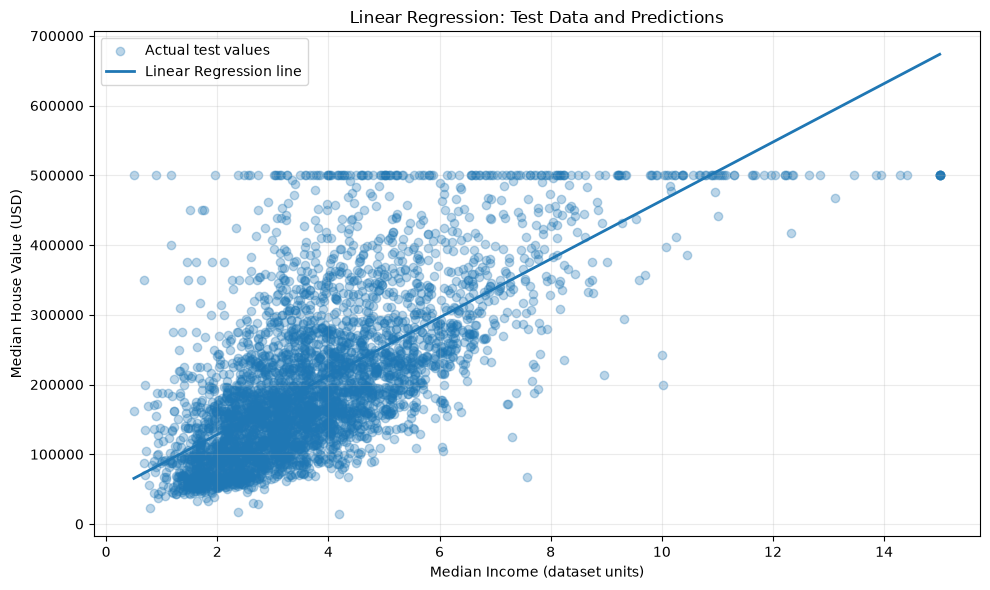

In [10]:
x_test_values = X_test["median_income"].to_numpy()
sort_order = np.argsort(x_test_values)

plt.figure(figsize=(10, 6))
plt.scatter(
    x_test_values,
    y_test.to_numpy(),
    alpha=0.3,
    label="Actual test values"
)
plt.plot(
    x_test_values[sort_order],
    y_pred[sort_order],
    linewidth=2,
    label="Linear Regression line"
)
plt.xlabel("Median Income (dataset units)")
plt.ylabel("Median House Value (USD)")
plt.title("Linear Regression: Test Data and Predictions")
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretation:** The regression line shows the values predicted from median income. The vertical distance between a point and the line represents its prediction residual. A wide spread around the line indicates that income alone does not explain all differences in house values.

##  10. Results and Interpretation

Linear Regression was used to predict median house value based on median income using two selected variables. After removing records with missing values, the dataset contained 20,640 observations. The dataset was divided into 80% training data (16,512 records) and 20% testing data (4,128 records).

The model achieved a Mean Absolute Error (MAE) of **$62,990.87**, a Mean Squared Error (MSE) of approximately **7.09 billion**, a Root Mean Squared Error (RMSE) of **$84,209.01**, and an R-squared (R²) value of **0.4589**.

The scatter plot indicates a positive relationship between median income and median house value. However, the data points are widely distributed around the regression line, indicating that income alone does not fully explain housing prices. The R² value suggests that the model explains approximately 45.89% of the variation in the test-set house values.

Overall, Linear Regression identified a positive relationship between the two variables, but its predictions have considerable error. Other factors, such as location, housing characteristics, and local market conditions, may also influence house values but were not included in this model.